# Recipe R-MOD-001: Simulasi Difusi Panas Satu Dimensi

| | |
|---|---|
| **Nama** | Muhammad Fikri Aliyuddin |
| **NIM** | H061241051 |
| **Kelas** | C |
| **Tugas** | Project 3 – Artificial Intelligence |

---

Berdasarkan *AI Cookbook untuk Earth Sciences* yang dilampirkan, recipe ini mengimplementasikan pemodelan difusi panas satu dimensi menggunakan metode *explicit finite difference*.

**Skenario fisis:** bayangkan tanah dengan suhu awal seragam 10 °C. Tiba-tiba permukaannya dipanaskan dan dijaga tetap 25 °C (misalnya akibat paparan panas dari permukaan). Pertanyaannya: *bagaimana panas itu merambat ke bawah selama 30 hari?*

**Alur notebook:**
1. Teori dan kriteria kestabilan.
2. Menyiapkan parameter dan grid.
3. Menjalankan simulasi.
4. Visualisasi (heatmap dan profil suhu).
5. Validasi terhadap solusi analitik.
6. Demonstrasi: apa yang terjadi jika syarat kestabilan dilanggar.

## 1. Teori Minimal (E-HEAT-001)
Persamaan difusi panas:
$$ \frac{\partial T}{\partial t} = \kappa \frac{\partial^2 T}{\partial z^2} $$
dengan $T$ (suhu, °C), $z$ (kedalaman, m), $t$ (waktu, s), dan $\kappa$ (difusivitas termal, m²/s).

**Arti fisisnya:** laju perubahan suhu di suatu titik sebanding dengan kelengkungan profil suhu di titik itu ($\partial^2 T/\partial z^2$). Kalau suhu di sekitar titik lebih tinggi dari rata-rata titik itu sendiri, suhunya naik, dan sebaliknya. Semakin besar $\kappa$, panas merambat semakin cepat.

### Diskretisasi (metode eksplisit, FTCS)
Turunan diganti selisih hingga: *forward* di waktu, *central* di ruang. Hasilnya, suhu di langkah waktu berikutnya dihitung langsung dari langkah sekarang:

$$ T_i^{n+1} = T_i^{n} + r\left(T_{i+1}^{n} - 2T_i^{n} + T_{i-1}^{n}\right), \qquad r = \frac{\kappa\,\Delta t}{\Delta z^2} $$

*   $i$ = indeks kedalaman, $n$ = indeks waktu.
*   Secara intuitif, suhu baru adalah suhu lama ditambah "koreksi" dari tetangga kiri dan kanan.

### Syarat kestabilan
Syarat kestabilan metode eksplisit adalah $r = \kappa \Delta t / \Delta z^2 \le 1/2$. Jika dilanggar, galat numerik membesar tiap langkah waktu dan hasilnya meledak (nilai tidak masuk akal). Jadi $\Delta t$ tidak bisa dipilih sembarangan: $\Delta t \le \Delta z^2 / (2\kappa)$.

## 2. Parameter Model dan Pengecekan Kestabilan
Kita tentukan sifat material dan ukuran grid, lalu cek dulu kestabilannya sebelum simulasi dijalankan.

*   `kappa = 1e-6 m²/s` adalah nilai tipikal untuk tanah/batuan.
*   `dz = 0.1 m` dan `dt = 3600 s` (1 jam).
*   Kalau $r > 0.5$, simulasi dihentikan dengan error (bukan sekadar peringatan), supaya tidak ada yang tidak sengaja memakai hasil yang meledak.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Parameter Model (Berdasarkan Recipe)
kappa = 1.0e-6  # Thermal diffusivity (m^2/s)
z_max = 5.0     # Kedalaman maksimum (m)
t_max = 30 * 24 * 3600  # Durasi simulasi (30 hari dalam detik)

dz = 0.1  # Resolusi spasial (m)
dt = 3600 # Resolusi waktu (detik) - 1 jam

# Cek kestabilan
r = kappa * dt / (dz**2)
print(f"Rasio kestabilan (r): {r:.4f}")
if r > 0.5:
    raise ValueError("Kriteria kestabilan tidak terpenuhi (r > 0.5)! Perkecil dt atau perbesar dz.")
print("Kriteria kestabilan terpenuhi (r <= 0.5).")

# Dt maksimum yang masih stabil untuk dz ini (info tambahan)
dt_max = dz**2 / (2 * kappa)
print(f"dt maksimum yang stabil untuk dz = {dz} m adalah {dt_max:.0f} s ({dt_max/3600:.2f} jam)")

Rasio kestabilan (r): 0.3600
Kriteria kestabilan terpenuhi (r <= 0.5).
dt maksimum yang stabil untuk dz = 0.1 m adalah 5000 s (1.39 jam)


## 3. Solusi Numerik
Proses iterasi waktu dan ruang menggunakan metode *finite difference*.

**Perubahan kecil dari versi awal:**
*   Grid dibuat dengan `np.linspace` dan jumlah titik dihitung dengan `round(...)`. `np.arange` dengan bilangan desimal (0.1) berisiko menghasilkan jumlah titik yang berbeda satu akibat pembulatan floating-point.
*   Loop kedalaman (`for i in ...`) diganti operasi **vektor** NumPy. Hasilnya sama persis, tetapi jauh lebih cepat; ini kita buktikan di sel verifikasi di bawah.

**Kondisi awal dan batas:**
*   Awal ($t=0$): suhu 10 °C di semua kedalaman, kecuali permukaan.
*   Batas atas ($z=0$): dijaga 25 °C setiap saat (kondisi Dirichlet).
*   Batas bawah ($z=5$ m): dijaga 10 °C (kondisi Dirichlet).

In [2]:
# Inisialisasi Grid
nz = int(round(z_max / dz)) + 1
nt = int(round(t_max / dt)) + 1
z = np.linspace(0, z_max, nz)
t = np.linspace(0, t_max, nt)

# Matriks Suhu T[time, depth]
T = np.zeros((nt, nz))

# Kondisi Awal (Initial Condition): Suhu awal 10 Celcius di semua kedalaman
T[0, :] = 10.0

# Kondisi Batas (Boundary Conditions)
# Suhu permukaan (z=0) naik menjadi 25 Celcius (Gangguan panas dari permukaan)
T[:, 0] = 25.0
# Suhu dasar (z=z_max) tetap 10 Celcius
T[:, -1] = 10.0

# Simulasi Finite Difference (Eksplisit), versi vektor
for n in range(nt - 1):
    T[n+1, 1:-1] = T[n, 1:-1] + r * (T[n, 2:] - 2*T[n, 1:-1] + T[n, :-2])

print(f"Ukuran grid: {nz} titik kedalaman x {nt} langkah waktu")
print("Simulasi finite difference selesai.")

# Verifikasi: versi loop asli (lambat) harus memberi hasil yang sama
T_loop = T.copy()
T_loop[1:, 1:-1] = 0.0
for n in range(nt - 1):
    for i in range(1, nz - 1):
        T_loop[n+1, i] = T_loop[n, i] + r * (T_loop[n, i+1] - 2*T_loop[n, i] + T_loop[n, i-1])
print(f"Selisih maksimum versi vektor vs loop asli = {np.abs(T - T_loop).max():.2e} °C")

Ukuran grid: 51 titik kedalaman x 721 langkah waktu
Simulasi finite difference selesai.
Selisih maksimum versi vektor vs loop asli = 0.00e+00 °C


## 4. Visualisasi
Visualisasi hasil akhir simulasi evolusi suhu terhadap kedalaman dan waktu dalam bentuk *heatmap*, seperti yang diinstruksikan dalam Prompt P-MOD-001.

Cara membaca heatmap: sumbu-x adalah waktu, sumbu-y adalah kedalaman (0 di atas, bertambah ke bawah), warna adalah suhu. Warna terang di bagian atas adalah sumber panas (25 °C) dan "lidah" terang yang makin menjalar ke bawah menunjukkan panas yang merambat.

Di sebelahnya kita tambahkan **profil suhu vs kedalaman** pada beberapa waktu, yang lebih mudah dibaca secara kuantitatif daripada warna.

Panjang difusi setelah 30 hari, sqrt(kappa*t) = 1.61 m


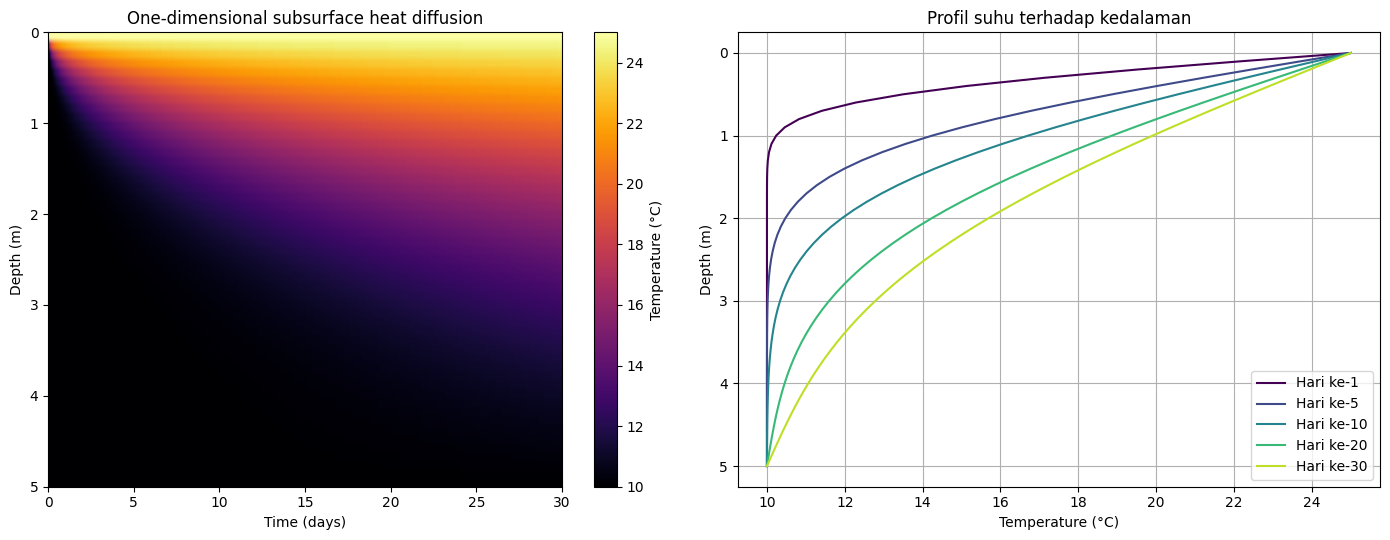

In [3]:
fig, axs = plt.subplots(1, 2, figsize=(14, 5.5))

# (a) Heatmap
im = axs[0].imshow(T.T, aspect='auto', cmap='inferno',
                   extent=[0, t_max/(24*3600), z_max, 0])
fig.colorbar(im, ax=axs[0], label='Temperature (°C)')
axs[0].set_xlabel('Time (days)')
axs[0].set_ylabel('Depth (m)')
axs[0].set_title('One-dimensional subsurface heat diffusion')

# (b) Profil suhu pada beberapa waktu
for hari, warna in zip([1, 5, 10, 20, 30], plt.cm.viridis(np.linspace(0, 0.9, 5))):
    n = int(hari * 24 * 3600 / dt)
    axs[1].plot(T[n], z, color=warna, label=f'Hari ke-{hari}')
axs[1].invert_yaxis()   # kedalaman bertambah ke bawah
axs[1].set_xlabel('Temperature (°C)')
axs[1].set_ylabel('Depth (m)')
axs[1].set_title('Profil suhu terhadap kedalaman')
axs[1].grid(True)
axs[1].legend()

plt.tight_layout()
plt.show()

# Panjang difusi: seberapa dalam panas "terasa" setelah waktu t  ->  L ~ sqrt(kappa * t)
L = np.sqrt(kappa * t_max)
print(f"Panjang difusi setelah 30 hari, sqrt(kappa*t) = {L:.2f} m")

## 5. Validasi terhadap Solusi Analitik
Hasil numerik perlu dicek benar atau tidaknya. Untuk masalah ini ada solusi eksak pada medium setengah-tak-hingga (suhu permukaan konstan $T_s$, suhu awal $T_0$):

$$ T(z,t) = T_s + (T_0 - T_s)\,\mathrm{erf}\!\left(\frac{z}{2\sqrt{\kappa t}}\right) $$

**Catatan penting:** model numerik kita punya dasar tetap 10 °C di $z = 5$ m, sedangkan solusi analitik mengasumsikan medium tak terbatas ke bawah. Karena panjang difusi setelah 30 hari sekitar 1,6 m, panas sudah cukup mendekati dasar sehingga kedua model **berbeda di dekat dasar**, bukan karena kode salah. Maka perbandingan yang adil dilakukan di kedalaman $z \le 3$ m, jauh dari pengaruh batas bawah.

Selisih maksimum |numerik - analitik| untuk z <= 3 m:
  hari ke- 5: 0.0158 °C
  hari ke-15: 0.0053 °C
  hari ke-30: 0.0296 °C

Selisih maksimum seluruh kedalaman (hari ke-30): 0.421 °C, terjadi di z = 5.0 m (dekat dasar, karena efek batas bawah)


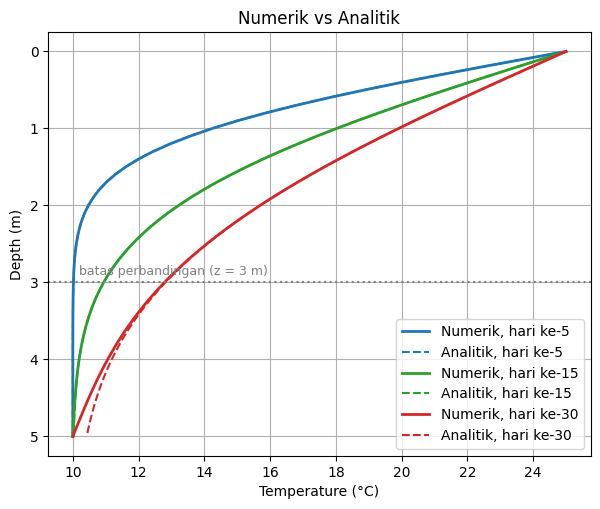

In [4]:
from math import erf

Ts, T0 = 25.0, 10.0

def T_analitik(z_arr, t_detik):
    return np.array([Ts + (T0 - Ts) * erf(zz / (2 * np.sqrt(kappa * t_detik))) for zz in z_arr])

fig, ax = plt.subplots(figsize=(7, 5.5))
for hari, warna in zip([5, 15, 30], ['tab:blue', 'tab:green', 'tab:red']):
    n = int(hari * 24 * 3600 / dt)
    ax.plot(T[n], z, color=warna, linewidth=2, label=f'Numerik, hari ke-{hari}')
    ax.plot(T_analitik(z, hari * 24 * 3600), z, color=warna, linestyle='--', label=f'Analitik, hari ke-{hari}')
ax.axhline(3.0, color='gray', linestyle=':')
ax.text(10.2, 2.9, 'batas perbandingan (z = 3 m)', color='gray', fontsize=9)
ax.invert_yaxis()
ax.set_xlabel('Temperature (°C)')
ax.set_ylabel('Depth (m)')
ax.set_title('Numerik vs Analitik')
ax.grid(True)
ax.legend()
plt.show()

mask = z <= 3.0
print("Selisih maksimum |numerik - analitik| untuk z <= 3 m:")
for hari in [5, 15, 30]:
    n = int(hari * 24 * 3600 / dt)
    beda = np.abs(T[n][mask] - T_analitik(z[mask], hari * 24 * 3600))
    print(f"  hari ke-{hari:>2}: {beda.max():.4f} °C")
n = nt - 1
beda_penuh = np.abs(T[n] - T_analitik(z, t_max))
print(f"\nSelisih maksimum seluruh kedalaman (hari ke-30): {beda_penuh.max():.3f} °C, "
      f"terjadi di z = {z[beda_penuh.argmax()]:.1f} m (dekat dasar, karena efek batas bawah)")

## 6. Apa yang Terjadi Jika Syarat Kestabilan Dilanggar?
Supaya jelas kenapa pengecekan $r \le 0.5$ penting, kita jalankan simulasi singkat yang sama dengan $\Delta t$ dibuat terlalu besar ($r = 0.6$) dan bandingkan dengan $r = 0.36$ (kita pakai). Suhu fisis seharusnya selalu berada di antara 10 dan 25 °C.

r = 0.36: suhu minimum = 10 °C, maksimum = 25 °C
r = 0.60: suhu minimum = -1.78e+27 °C, maksimum = 1.77e+27 °C


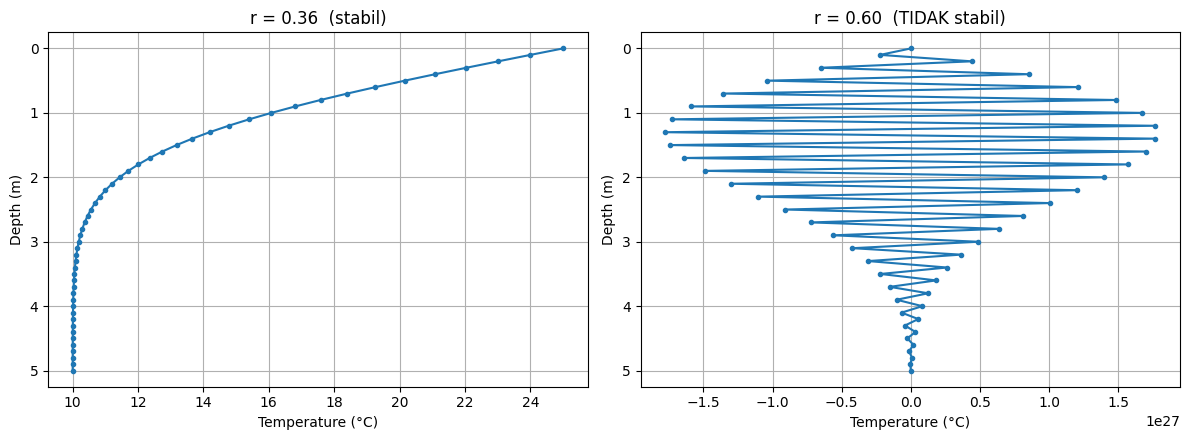

In [5]:
def simulasi(r_uji, n_langkah=200):
    u = np.full(nz, 10.0); u[0] = 25.0; u[-1] = 10.0
    for _ in range(n_langkah):
        u[1:-1] = u[1:-1] + r_uji * (u[2:] - 2*u[1:-1] + u[:-2])
    return u

fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, r_uji in zip(axs, [r, 0.6]):
    u = simulasi(r_uji)
    ax.plot(u, z, 'o-', markersize=3)
    ax.invert_yaxis()
    ax.set_title(f'r = {r_uji:.2f}  ({"stabil" if r_uji <= 0.5 else "TIDAK stabil"})')
    ax.set_xlabel('Temperature (°C)')
    ax.set_ylabel('Depth (m)')
    ax.grid(True)
    print(f"r = {r_uji:.2f}: suhu minimum = {u.min():.3g} °C, maksimum = {u.max():.3g} °C")
plt.tight_layout()
plt.show()

## 7. Diskusi dan Kesimpulan

1. **Kestabilan:** dengan $\kappa = 10^{-6}$ m²/s, $\Delta z = 0.1$ m, $\Delta t = 3600$ s diperoleh $r = 0{,}36 \le 0{,}5$, jadi simulasi stabil. $\Delta t$ maksimum yang masih stabil adalah 5000 s (≈ 1,39 jam), jadi pilihan 1 jam cukup aman.

2. **Perilaku fisis hasil simulasi:**
   * Panas merambat dari permukaan ke bawah; makin lama, makin dalam panas terasa. Suhu di bawah tidak pernah melebihi 25 °C maupun turun di bawah 10 °C (prinsip maksimum difusi).
   * Pada hari ke-30, suhu di kedalaman 1 m sekitar 19,9 °C, di 2 m sekitar 15,7 °C, dan di 3 m sekitar 12,8 °C. Di dasar (5 m) tetap 10 °C karena dipaksa oleh kondisi batas.
   * Kedalaman jangkauan panas mengikuti $\sqrt{\kappa t}$ (≈ 1,6 m untuk 30 hari). Artinya, **memperpanjang waktu 4 kali lipat hanya menambah kedalaman jangkauan 2 kali lipat**. Difusi panas di tanah itu lambat.

3. **Validasi:** untuk $z \le 3$ m, selisih antara hasil numerik dan solusi analitik hanya sekitar 0,03 °C atau kurang (lihat keluaran Bagian 5), jadi kode benar. Selisih yang lebih besar (≈ 0,4 °C) hanya muncul di dekat dasar akibat perbedaan kondisi batas, bukan kesalahan perhitungan.

4. **Ketidakstabilan:** pada $r = 0{,}6$ solusi meledak ke nilai yang jauh di luar 10–25 °C, sementara $r = 0{,}36$ tetap wajar. Ini menegaskan bahwa kriteria $r \le 0{,}5$ harus dipenuhi.

5. **Keterbatasan model:**
   * Satu dimensi dan $\kappa$ seragam; tanah nyata berlapis dengan $\kappa$ berbeda dan ada aliran air.
   * Suhu permukaan diasumsikan langsung naik dan konstan, padahal di alam berubah siklis (harian dan musiman).
   * Metode eksplisit membatasi $\Delta t$; kalau butuh grid yang sangat rapat, metode implisit (Crank–Nicolson) lebih efisien karena stabil untuk $r$ berapa pun.

**Kesimpulan:** simulasi *explicit finite difference* berhasil memodelkan perambatan panas 1D, stabil dan akurat dibanding solusi analitik. Perbaikan utama dibanding versi awal adalah: grid yang robust, pengecekan stabilitas yang menghentikan program, kode yang lebih cepat, plus validasi dan demonstrasi ketidakstabilan.